# Basic Image Enhancement Using Mathematical Operations
Image Processing techniques take advantage of mathematical operations to achieve different results. Most often we arrive at an enhanced version of the image using some basic operations. We will take a look at some of the fundamental operations often used in computer vision pipelines. In this notebook we will cover:

* Arithmetic Operations like addition, multiplication
* Thresholding & Masking
* Bitwise Operations like OR, AND, XOR

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image


In [5]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assets....", end="")

    urlretrieve(url, save_path)

    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])

        print("Done")
    except Exception as e:
        print("\nInvalid file.", e)

In [8]:
URL = r"https://www.dropbox.com/s/0oe92zziik5mwhf/opencv_bootcamp_assets_NB4.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), f"opencv_bootcamp_assets_NB4.zip")

# Download if assest ZIP does not exists. 
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)   


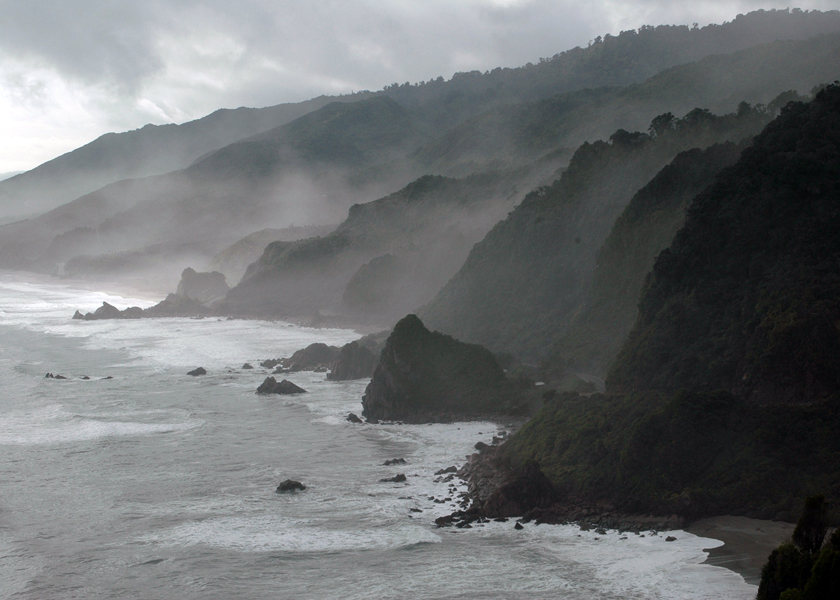

In [41]:
img_bgr = cv2.imread("New_Zealand_Coast.jpg", cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

Image(filename="New_Zealand_Coast.jpg")


__Addition or Brightness__

The first operation we discuss is simple addition of images. This results in increasing or decreasing the brightness of the image since we are eventually increasing or decreasing the intensity values of each pixel by the same amount. So, this will result in a global increase/decrease in brightness.

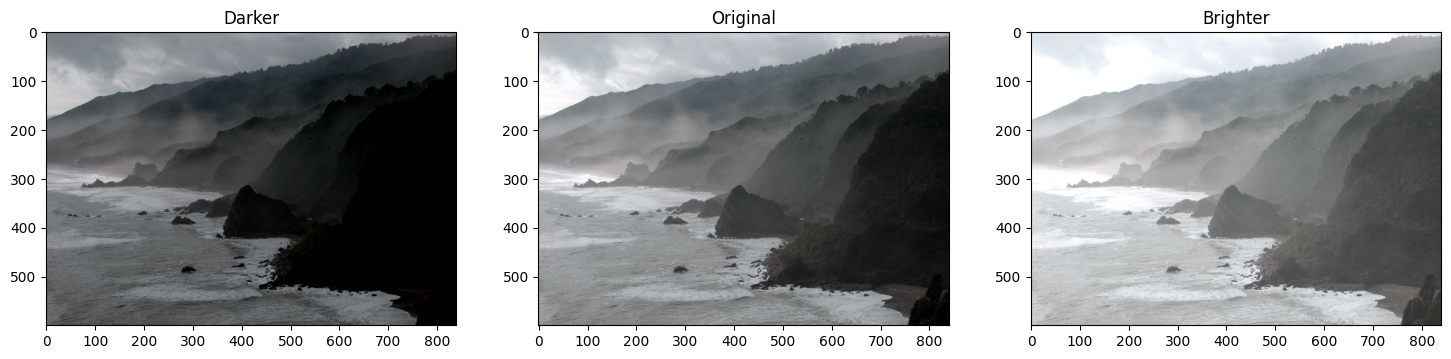

In [42]:
matrix = np.ones(img_rgb.shape, dtype = "uint8") * 50

img_rgb_brighter = cv2.add(img_rgb, matrix)
img_rgb_darker = cv2.subtract(img_rgb, matrix)

# Show the images
plt.figure(figsize = (18, 5))
plt.subplot(131); plt.imshow(img_rgb_darker); plt.title("Darker");
plt.subplot(132); plt.imshow(img_rgb);        plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_brighter); plt.title("Brighter")

plt.show()



In [43]:
matrix

array([[[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]],

       [[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]],

       [[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]],

       ...,

       [[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]],

       [[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]],

       [[50, 50, 50],
        [50, 50, 50],
        [50, 50, 50],
        ...,
        [50, 50, 50],
        [50, 50, 50],
        [50, 50, 50]]], dtype=uint8)

In [44]:
matrix.shape

(600, 840, 3)

# multiplication or contrast

Just like addition can result in brightness change, multiplication can be used to improve the contrast of the image.

Contrast is the difference in the intensity values of the pixels of an image. Multiplying the intensity values with a constant can make the difference larger or smaller ( if multiplying factor is < 1 )

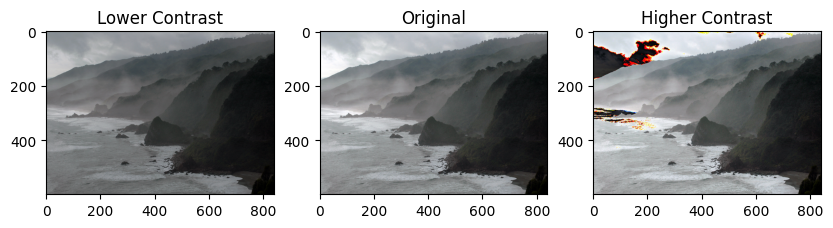

In [45]:
matrix1 = np.ones(img_rgb.shape) * 0.8
matrix2 = np.ones(img_rgb.shape) * 1.2

img_rgb_darker = np.uint8(cv2.multiply(np.float64(img_rgb), matrix1))
img_rgb_brighter = np.uint8(cv2.multiply(np.float64(img_rgb), matrix2))

# Show the images
plt.figure(figsize=(10, 5))
plt.subplot(131); plt.imshow(img_rgb_darker); plt.title("Lower Contrast");
plt.subplot(132); plt.imshow(img_rgb);       plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_brighter); plt.title("Higher Contrast");

plt.show()

__What happened?__

Can you see the weird colors in some areas of the image after multiplication?

The issue is that after multiplying, the values which are already high, are becoming greater than 255. Thus, the overflow issue. How do we overcome this?

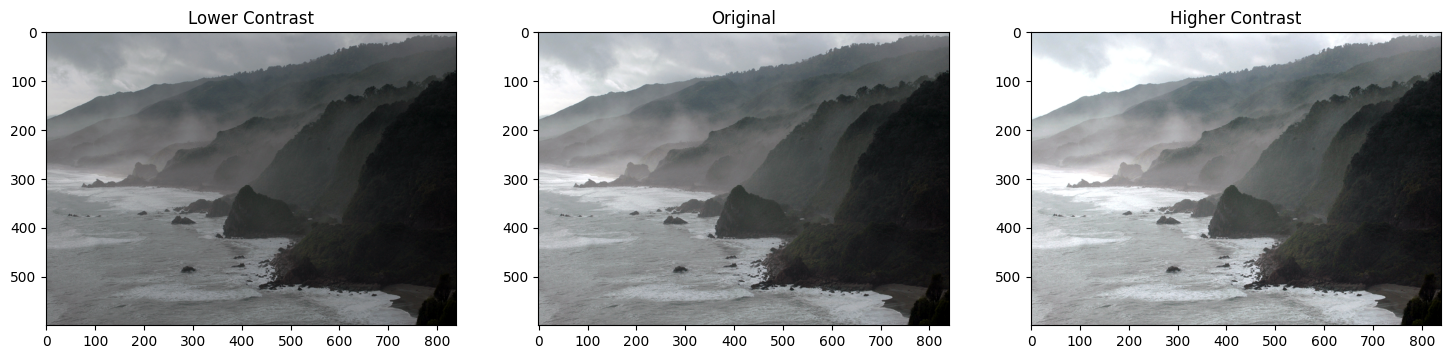

In [46]:
matrix1 = np.ones(img_rgb.shape) * .8
matrix2 = np.ones(img_rgb.shape) * 1.2

img_rgb_lower = np.uint8(cv2.multiply(np.float64(img_rgb), matrix1))
img_rgb_higher = np.uint8(np.clip(cv2.multiply(np.float64(img_rgb), matrix2), 0, 255))

# show the images
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_rgb_lower); plt.title("Lower Contrast");
plt.subplot(132); plt.imshow(img_rgb); plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_higher); plt.title("Higher Contrast");

plt.show()

# Image Thresholding
Binary Images have a lot of use cases in Image Processing. One of the most common use cases is that of creating masks. Image Masks allow us to process on specific parts of an image keeping the other parts intact. Image Thresholding is used to create Binary Images from grayscale images. You can use different thresholds to create different binary images from the same original image.

__Function Syntax__

retval, dst = cv2.threshold( src, thresh, maxval, type[, dst] )

__pixel values which are below thresh will become zero and above it will take the maxval__
dst: The output array of the same size and type and the same number of channels as src.


The function has 4 required arguments:

1. src: input array (multiple-channel, 8-bit or 32-bit floating point).

2. thresh: threshold value.

3. maxval: maximum value to use with the THRESH_BINARY and THRESH_BINARY_INV thresholding types.

4. type: thresholding type (see ThresholdTypes).

__Function Syntax__


dst = cv.adaptiveThreshold( src, maxValue, adaptiveMethod, thresholdType, blockSize, C[, dst] )
dst Destination image of the same size and the same type as src.

The function has __6 required arguments:__

1. src: Source 8-bit single-channel image.

2. maxValue: Non-zero value assigned to the pixels for which the condition is satisfied

3. adaptiveMethod: Adaptive thresholding algorithm to use, see AdaptiveThresholdTypes. The BORDER_REPLICATE | BORDER_ISOLATED is used to process boundaries.

4. thresholdType: Thresholding type that must be either THRESH_BINARY or THRESH_BINARY_INV, see ThresholdTypes.

5. blockSize: Size of a pixel neighborhood that is used to calculate a threshold value for the pixel: 3, 5, 7, and so on.

6. C: Constant subtracted from the mean or weighted mean (see the details below). Normally, it is positive but may be zero or negative as well.



# OpenCV Thresholding Types (`cv2.threshold`)

In OpenCV, the **`cv2.threshold(src, thresh, maxval, type)`** function applies a fixed-level threshold to each pixel in a single-channel image. The **`type`** parameter determines the thresholding rule applied.

---

## 1. Basic Threshold Types

| Threshold Flag | Mathematical Formula | Description |
| :--- | :--- | :--- |
| **`cv2.THRESH_BINARY`** | $\text{dst}(x,y) = \begin{cases} \text{maxValue} & \text{if } \text{src}(x,y) > \text{thresh} \\ 0 & \text{otherwise} \end{cases}$ | Pixels brighter than `thresh` turn white (`maxValue`); others turn black (`0`). |
| **`cv2.THRESH_BINARY_INV`** | $\text{dst}(x,y) = \begin{cases} 0 & \text{if } \text{src}(x,y) > \text{thresh} \\ \text{maxValue} & \text{otherwise} \end{cases}$ | Inverted version of `THRESH_BINARY`. Pixels brighter than `thresh` turn black (`0`); others turn white (`maxValue`). |
| **`cv2.THRESH_TRUNC`** | $\text{dst}(x,y) = \begin{cases} \text{thresh} & \text{if } \text{src}(x,y) > \text{thresh} \\ \text{src}(x,y) & \text{otherwise} \end{cases}$ | Truncates pixel values. Values above `thresh` become equal to `thresh`; values below remain unchanged. |
| **`cv2.THRESH_TOZERO`** | $\text{dst}(x,y) = \begin{cases} \text{src}(x,y) & \text{if } \text{src}(x,y) > \text{thresh} \\ 0 & \text{otherwise} \end{cases}$ | Pixels above `thresh` remain unchanged; pixels below `thresh` are set to `0` (black). |
| **`cv2.THRESH_TOZERO_INV`** | $\text{dst}(x,y) = \begin{cases} 0 & \text{if } \text{src}(x,y) > \text{thresh} \\ \text{src}(x,y) & \text{otherwise} \end{cases}$ | Inverted version of `THRESH_TOZERO`. Pixels above `thresh` are set to `0` (black); pixels below remain unchanged. |

---

## 2. Automatic Thresholding Flags

You can combine these flags with any of the basic types above using the bitwise OR operator (`|` or `+`) to calculate the optimal threshold automatically:

* **`cv2.THRESH_OTSU`**: Uses **Otsu's Binarization algorithm**, which works best on bimodal images (images with a dual-peak intensity histogram).
* **`cv2.THRESH_TRIANGLE`**: Uses the **Triangle Algorithm**, which works best on unimodal histograms with a single peak and long tail.

---

## Code Examples

### Standard Thresholding
```python
import cv2

# Read image in grayscale
img = cv2.imread('image.png', cv2.IMREAD_GRAYSCALE)

# Basic binary thresholding
ret, thresh_binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
ret, thresh_trunc = cv2.threshold(img, 127, 255, cv2.THRESH_TRUNC)

Automatic Thresholding (Otsu's Method)
When using automatic flags, set the thresh parameter to 0. OpenCV calculates the best value automatically and returns it in ret

# Otsu's thresholding combined with Binary Inverse
ret, thresh_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print(f"Optimal threshold found by Otsu: {ret}")

(572, 800)


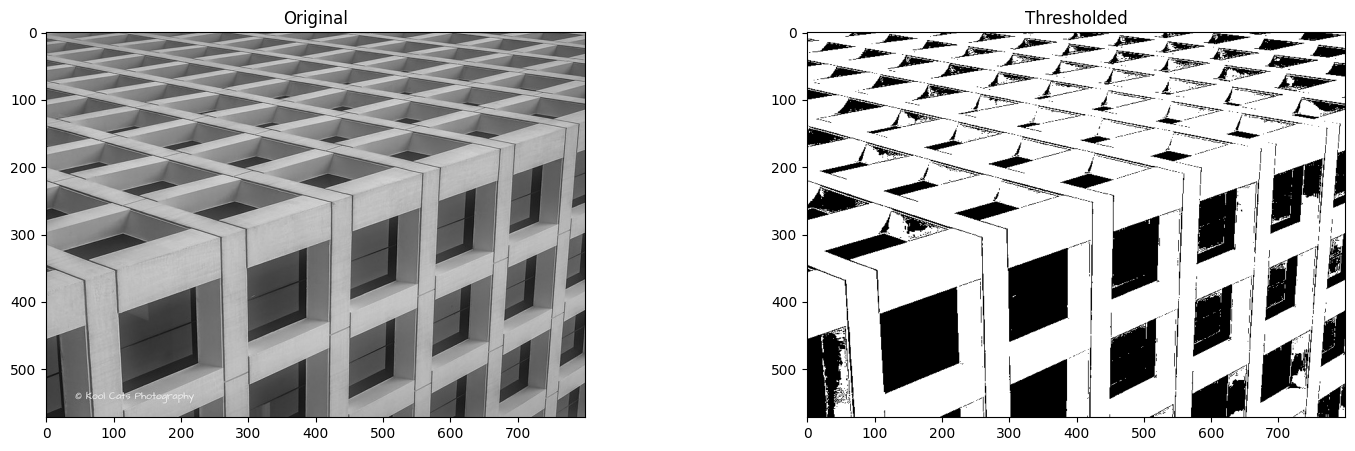

In [47]:
img_read = cv2.imread("building-windows.jpg", cv2.IMREAD_GRAYSCALE)
retval, img_thresh = cv2.threshold(img_read, 100, 255, cv2.THRESH_BINARY)

plt.figure(figsize=[18,5])
plt.subplot(121); plt.imshow(img_read, cmap="gray"); plt.title("Original");
plt.subplot(122); plt.imshow(img_thresh, cmap = "gray") ; plt.title("Thresholded");


print(img_thresh.shape)
plt.show()

(572, 800)


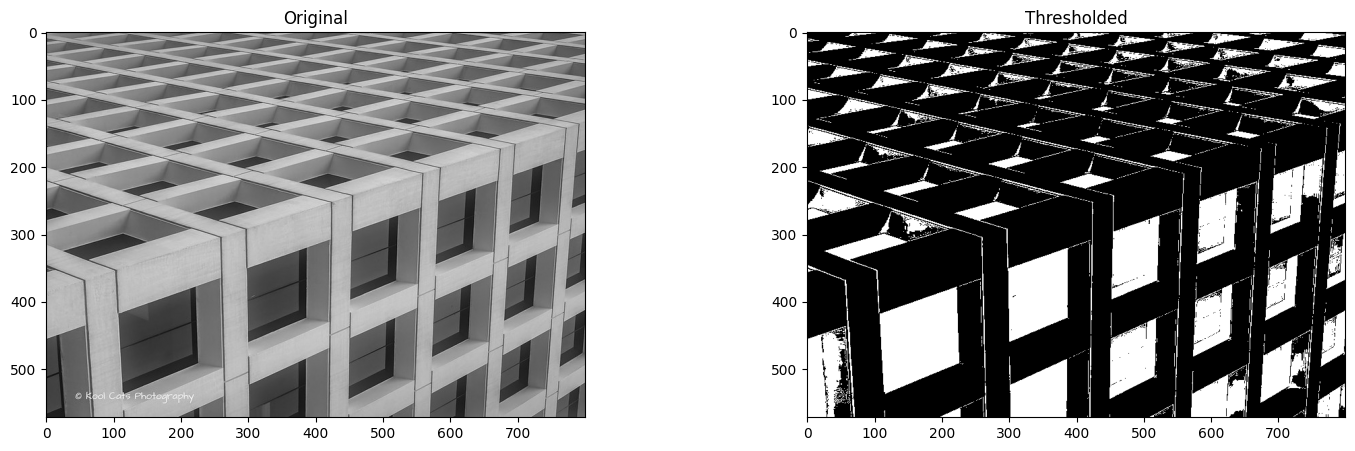

In [48]:
img_read = cv2.imread("building-windows.jpg", cv2.IMREAD_GRAYSCALE)
retval, img_thresh = cv2.threshold(img_read, 100, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=[18,5])
plt.subplot(121); plt.imshow(img_read, cmap="gray"); plt.title("Original");
plt.subplot(122); plt.imshow(img_thresh, cmap = "gray") ; plt.title("Thresholded");

print(img_thresh.shape)
plt.show()

# Application: Sheet Music Reader
Suppose you wanted to build an application that could read (decode) sheet music. This is similar to Optical Character Recognigition (OCR) for text documents where the goal is to recognize text characters. In either application, one of the first steps in the processing pipeline is to isolate the important information in the image of a document (separating it from the background). This task can be accomplished with thresholding techniques. Let's take a look at an example.

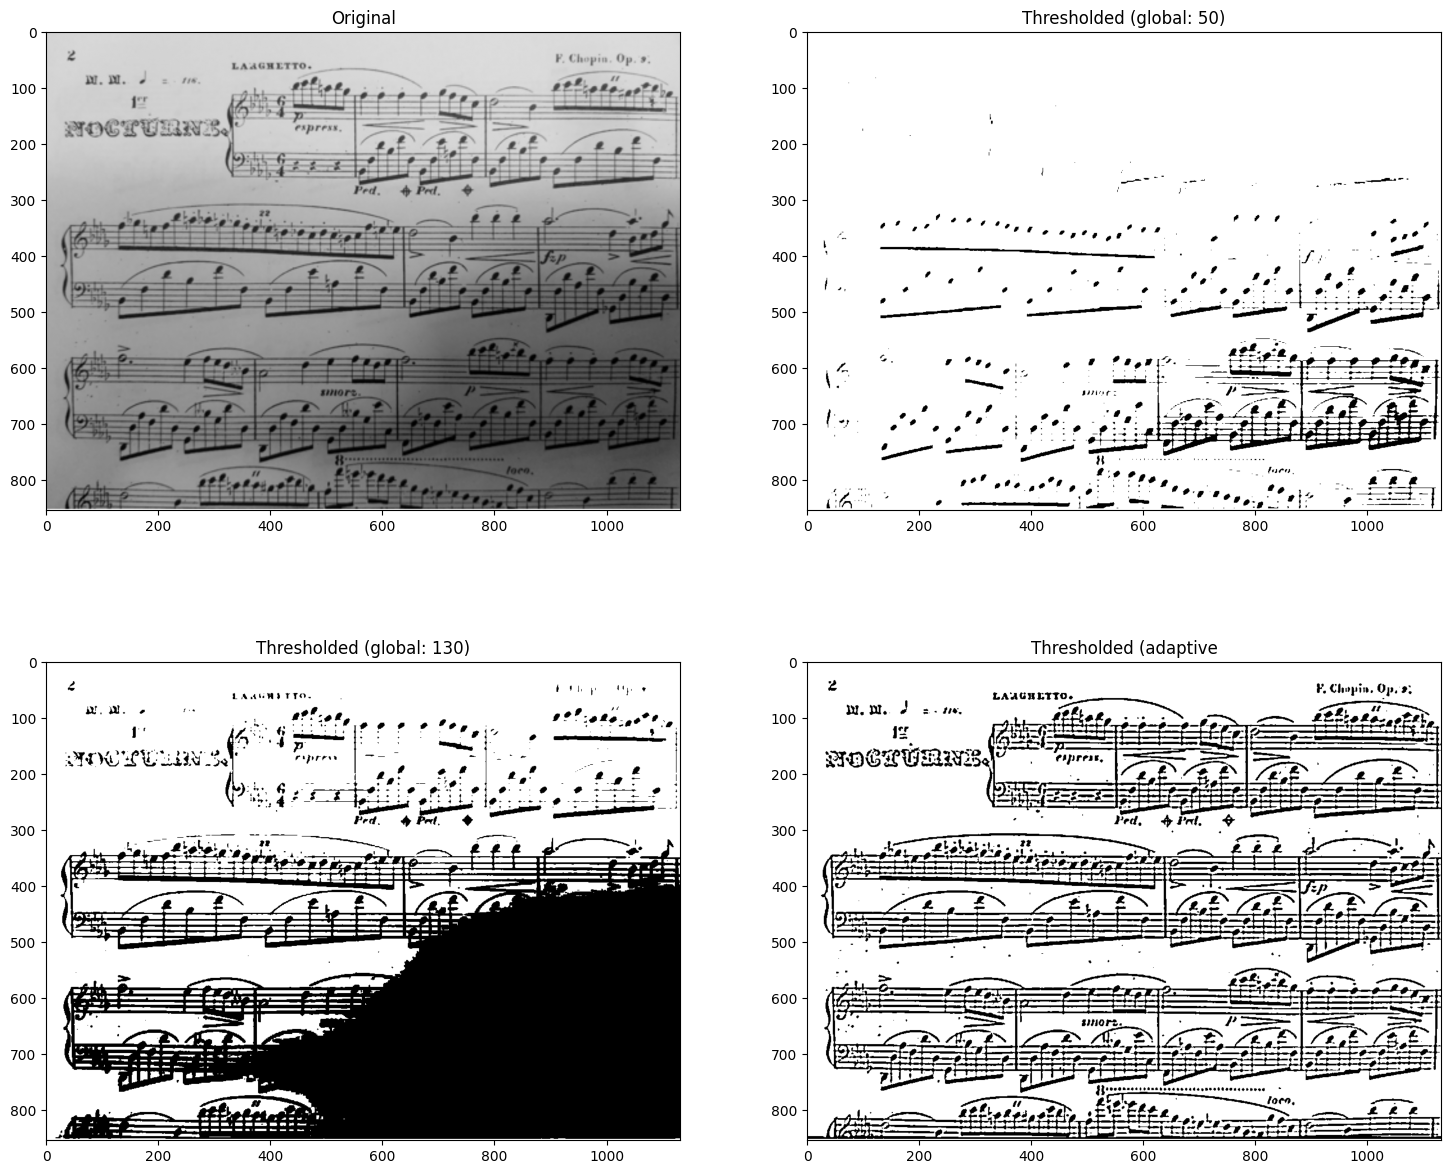

In [49]:
img_read = cv2.imread("Piano_Sheet_Music.png", cv2.IMREAD_GRAYSCALE)

retval, img_thresh_gbl_1 = cv2.threshold(img_read,50, 255, cv2.THRESH_BINARY)

retval, img_thresh_gbl_2 = cv2.threshold(img_read, 130, 255, cv2.THRESH_BINARY)

img_thresh_adp = cv2.adaptiveThreshold(img_read, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 7)

plt.figure(figsize=(18, 15))
plt.subplot(221); plt.imshow(img_read, cmap="gray"); plt.title("Original");
plt.subplot(222); plt.imshow(img_thresh_gbl_1, cmap="gray"); plt.title("Thresholded (global: 50)");
plt.subplot(223); plt.imshow(img_thresh_gbl_2, cmap="gray"); plt.title("Thresholded (global: 130)");
plt.subplot(224); plt.imshow(img_thresh_adp, cmap="gray"); plt.title("Thresholded (adaptive");

plt.show()

# Bitwise Operations
__Function Syntax__
Example API for cv2.bitwise_and(). Others include: cv2.bitwise_or(), cv2.bitwise_xor(), cv2.bitwise_not()

dst = cv2.bitwise_and( src1, src2[, dst[, mask]] )

dst: Output array that has the same size and type as the input arrays.

The function has __2 required arguments:__

1. src1: first input array or a scalar.

2. src2: second input array or a scalar.

An important optional argument is:

1. mask: optional operation mask, 8-bit single channel array, that specifies elements of the output array to be changed.

(200, 499)


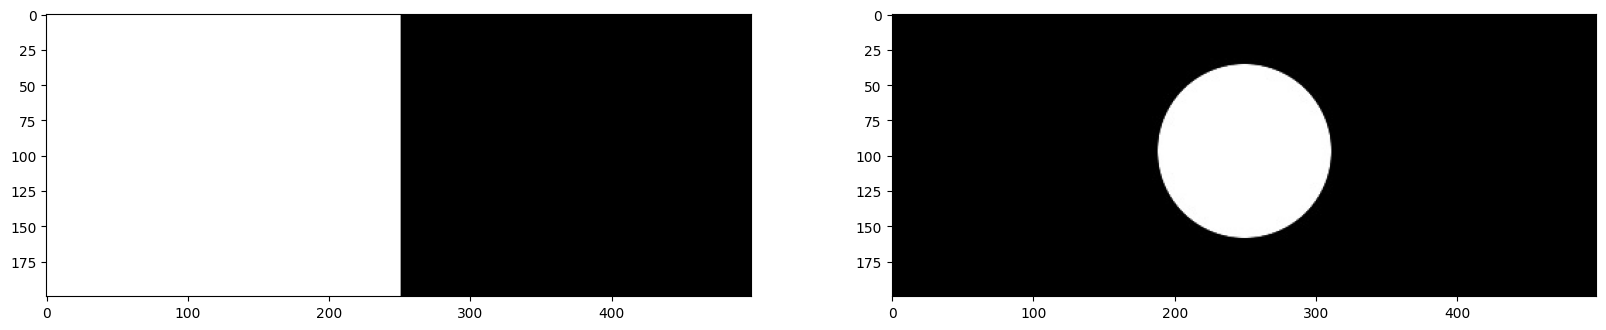

In [50]:
img_rec = cv2.imread("rectangle.jpg", cv2.IMREAD_GRAYSCALE)

img_cir = cv2.imread('circle.jpg', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=[20, 5])
plt.subplot(121); plt.imshow(img_rec, cmap="gray")
plt.subplot(122); plt.imshow(img_cir, cmap="gray")
print(img_rec.shape)

plt.show()

# Bitwise AND Operator

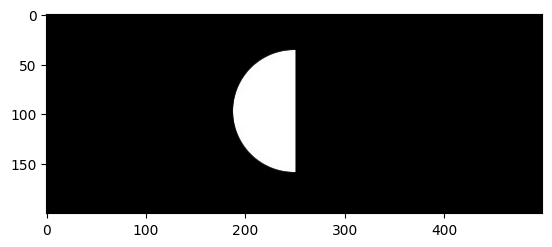

In [51]:
result = cv2.bitwise_and(img_rec, img_cir, mask= None)

plt.imshow(result, cmap="gray")
plt.show()

# Bitwise OR operator


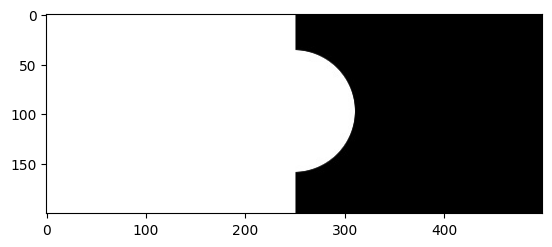

In [52]:
result = cv2.bitwise_or(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

plt.show()


# Bitwise XOR Operator

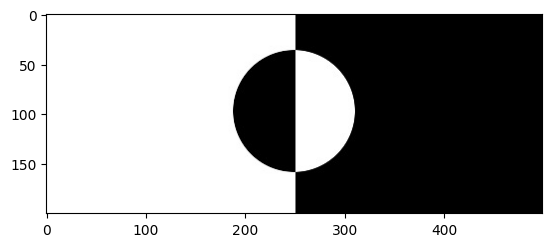

In [53]:
result = cv2.bitwise_xor(img_rec, img_cir, mask = None)
plt.imshow(result, cmap='gray')

plt.show()

# Application: Logo Manipulation

In this action we will show you how to fill in the while lettering of the Coca-Cola logo below with a background image.

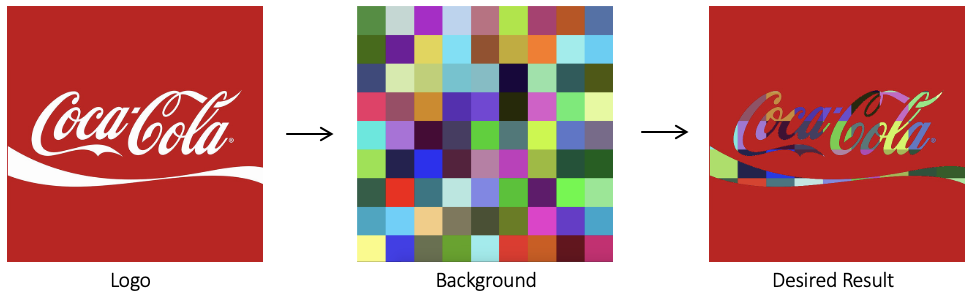

In [54]:
Image(filename='Logo_manipulation.png')


# <span style="color:green">Read Foreground Image</span>



(700, 700, 3)


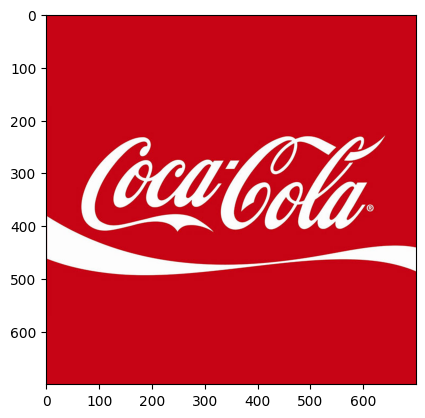

In [55]:
img_bgr = cv2.imread('coca-cola-logo.png')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2BGR)
plt.imshow(img_rgb)
print(img_rgb.shape)
logo_w = img_rgb.shape[0]
logo_h = img_rgb.shape[1]
plt.show()

# <span style="color:green">Read Background image<span>

(1800, 1800, 3)
(700, 700, 3)


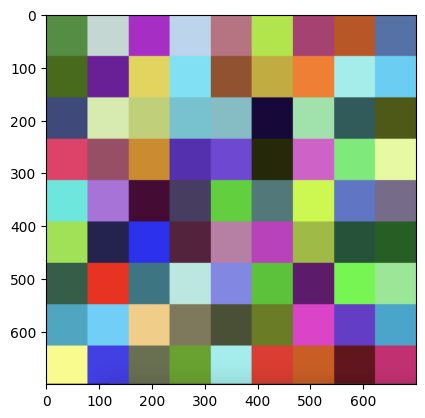

In [56]:
img_background_bgr  = cv2.imread("checkerboard_color.png")
img_background_rgb = cv2.cvtColor(img_background_bgr, cv2.COLOR_BGR2RGB)

aspect_ratio = logo_w / img_background_rgb.shape[1]
dim = (logo_w, int(img_background_rgb.shape[0] * aspect_ratio))
print(img_background_rgb.shape)

img_background_rgb = cv2.resize(img_background_rgb, dim, interpolation=cv2.INTER_AREA)

plt.imshow(img_background_rgb)
print(img_background_rgb.shape)

plt.show()

# <span span style="color:green"> Create Mask for original Image <span>

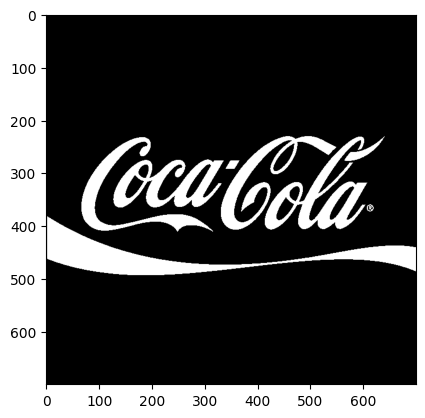

In [57]:
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

retval, img_mask = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img_mask, cmap = "gray")
plt.show()

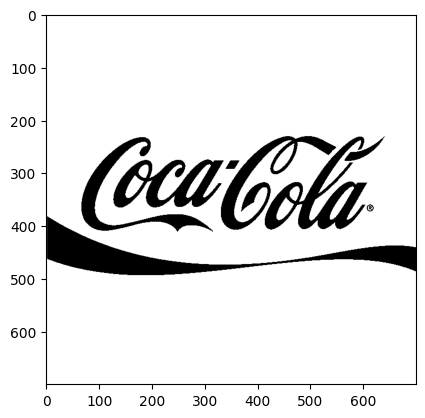

In [60]:
img_gray_inv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

retval, img_mask = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY_INV)

plt.imshow(img_mask, cmap = "gray")
plt.show()

# <span style="color:green"> Invert the mask <span>

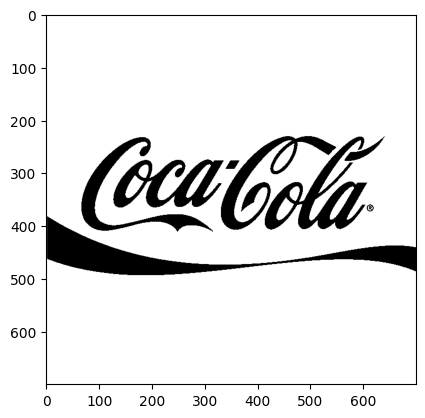

In [58]:
img_mask_inv = cv2.bitwise_not(img_mask)
plt.imshow(img_mask_inv, cmap="gray")
plt.show()

# <span style="color:green">Apply background on the mask<span>
    

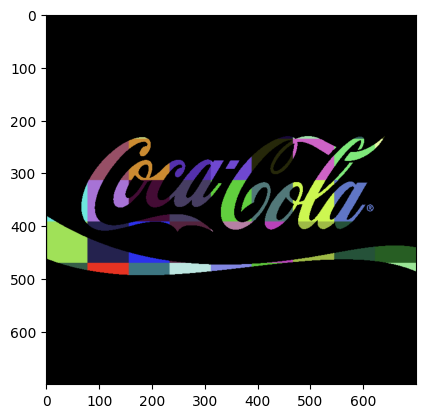

In [32]:
# create colorful background "behind" the logo lettering
img_background = cv2.bitwise_and(img_background_rgb, img_background_rgb, mask = img_mask)
plt.imshow(img_background)
plt.show()

# <span style="color:green">Isolate foreground from image<span>


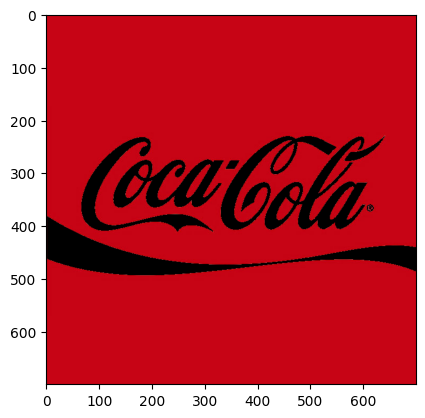

In [34]:
# Isolate foreground (red from original image) using  the inverse mask
img_foreground = cv2.bitwise_and(img_rgb, img_rgb, mask = img_mask_inv)
plt.imshow(img_foreground)
plt.show()

# <span style="color:green"> Result: Merge Foreground and Background<span>

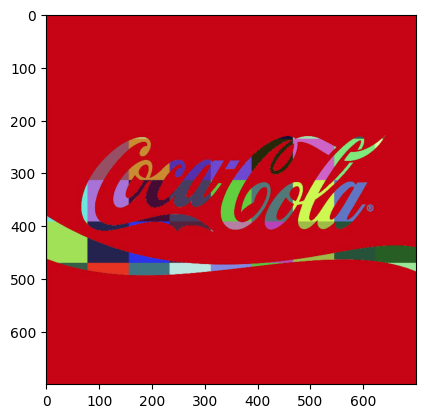

In [36]:
# Add the two previous results obtain the final result

result = cv2.add(img_background, img_foreground)
plt.imshow(result)

cv2.imwrite("logo_final.png", result[:,:,::-1])
plt.show()

In [61]:
arr1 = np.array([200, 250], dtype=np.uint8).reshape(-1, 1)
arr2 = np.array([40, 40], dtype=np.uint8).reshape(-1, 1)

In [82]:
arr1

array([[200],
       [250]], dtype=uint8)

In [63]:
arr2

array([[40],
       [40]], dtype=uint8)

In [71]:
arr1.shape

(2, 1)

In [72]:
arr2.shape

(2, 1)

In [64]:
add_numpy = arr1+arr2
add_numpy

array([[240],
       [ 34]], dtype=uint8)

In [69]:
add_numpy.shape

(2, 1)

In [65]:
add_cv2 = cv2.add(arr1, arr2)
add_cv2

array([[240],
       [255]], dtype=uint8)

In [70]:
add_cv2.shape

(2, 1)